# Employment and Output

How are recorded economic output and employment associated?

Data: [datasets/longley](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/longley.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Only 16 annual observations; common trends and collinearity can create misleading correlations.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Employment and Output',
 'executed_utc': '2026-11-21T10:14:13.014500+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/longley.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/longley.html',
 'sha256': '1283706d84cb7697111b42a6aed3aca222df1cda2ed1c3d4913b713b94a5e516',
 'raw_rows': 16,
 'analysis_rows': 16,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8',
 'pearson': 0.9835516111796692,
 'spearman': 0.9852941176470589}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,16
1,GNP.deflator,float64,0,0.0,16
2,GNP,float64,0,0.0,16
3,Unemployed,float64,0,0.0,16
4,Armed.Forces,float64,0,0.0,16
5,Population,float64,0,0.0,16
6,Year,int64,0,0.0,16
7,Employed,float64,0,0.0,16


## SQL and analysis
Complete-pair scatter plot of GNP and Employed, with Pearson and Spearman correlations. No regression adjustment or causal claim.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "GNP" AS predictor, "Employed" AS outcome FROM observations ORDER BY "GNP";

Among 16 complete observations, Pearson r = 0.984 and Spearman rho = 0.985.


,predictor,outcome
0,234.289,60.323
1,258.054,60.171
2,259.426,61.122
3,284.599,61.187
4,328.975,63.221
5,346.999,63.639
6,363.112,63.761
7,365.385,64.989
8,397.469,66.019
9,419.180,67.857


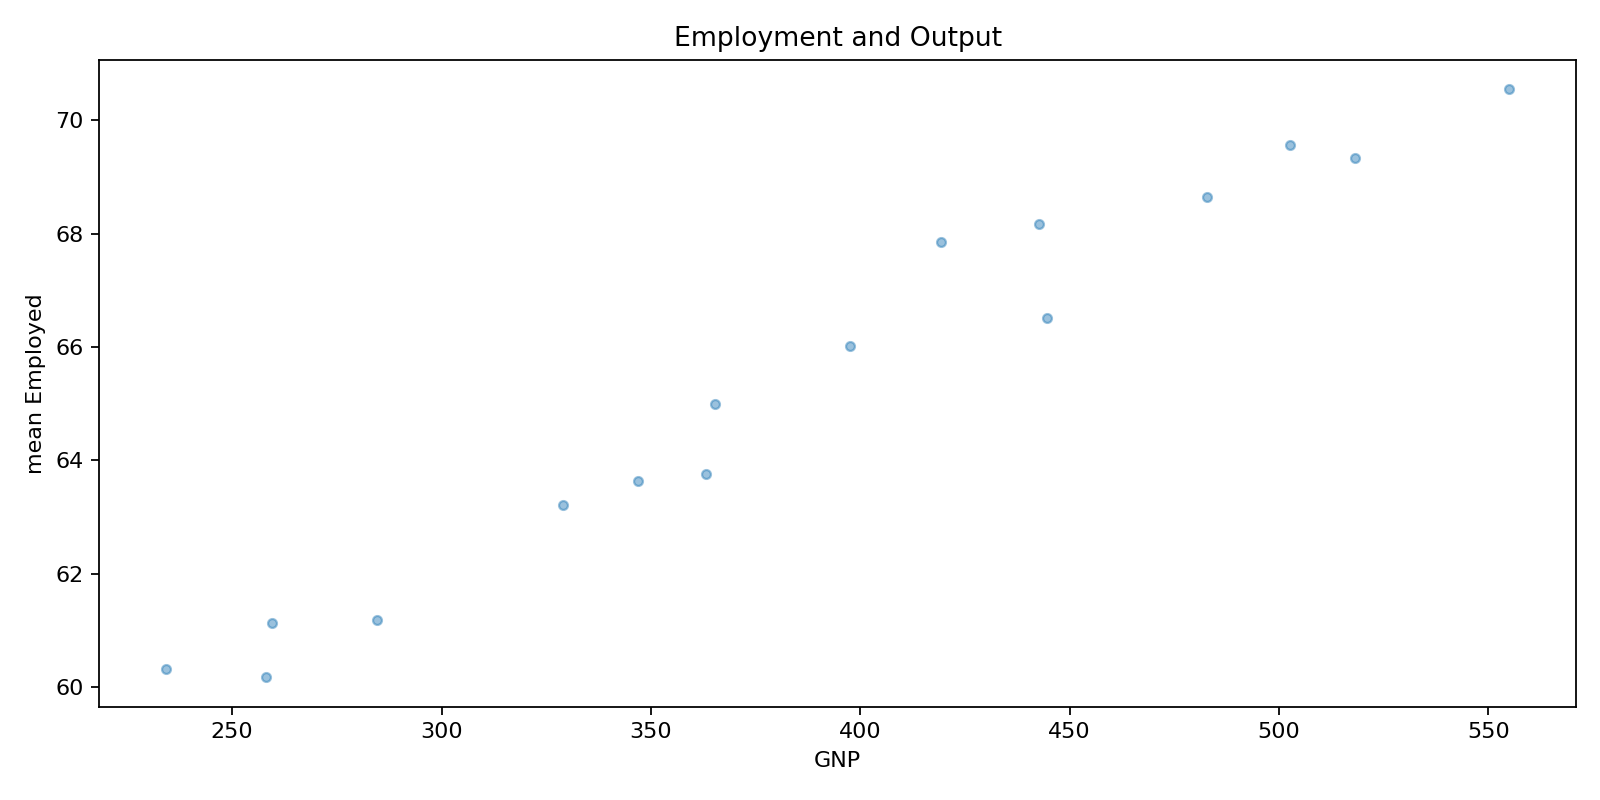

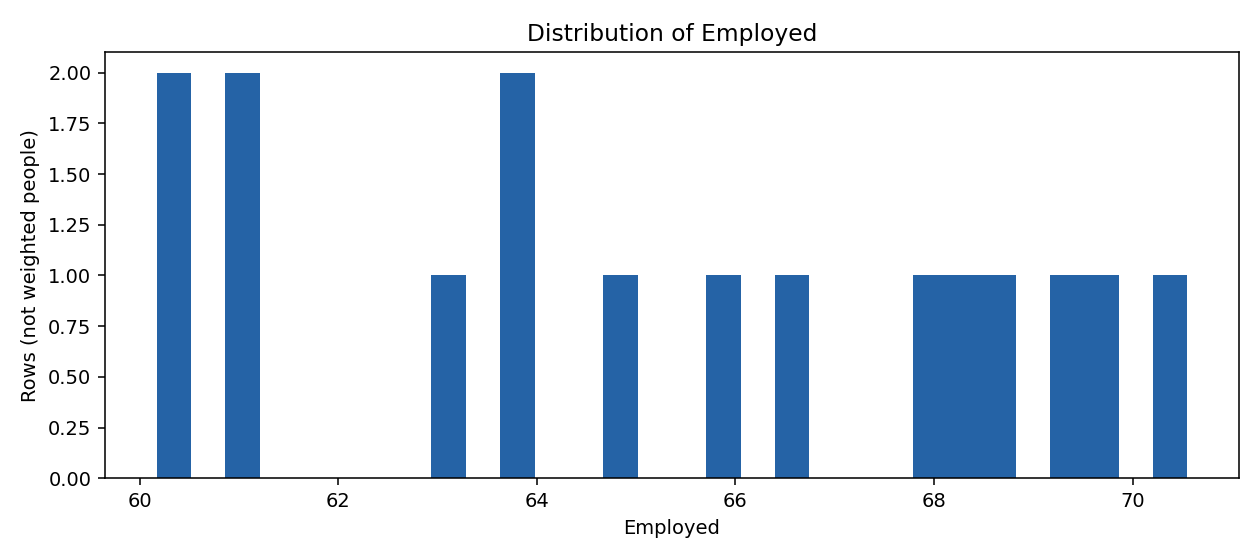

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Only 16 annual observations; common trends and collinearity can create misleading correlations.

**Next action:** Difference the series and inspect time dependence before modelling.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.